# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [23]:
!pip -q install -U ddgs

In [24]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

### Respuesta TODO 1

1. **Clases:** `bus`, `motorcycle` y `bicycle`.
2. **Términos de búsqueda:** para cada clase usé tres, en inglés y español (por ejemplo, "city bus on the street", "motorbike side view" y "bicicleta urbana"), para que los resultados no dependan de un solo idioma ni de un solo tipo de foto.
3. **Hipótesis visual:** espero que el modelo use el **tamaño y la forma general** (un bus es grande y rectangular, con muchas ventanas; la moto y la bicicleta son delgadas) y, entre estas dos últimas, la presencia de **motor, tanque y llantas más gruesas** en la moto frente al marco delgado y los radios finos de la bicicleta.
4. **Posible sesgo / data leakage:** (a) los buscadores devuelven imágenes casi idénticas o la misma foto en distintas resoluciones; si una copia cae en train y otra en test, la evaluación sale inflada. (b) Las fotos de bus suelen estar en la calle y las de bicicleta en ciclovías o parques, así que el modelo podría aprender el **fondo** en lugar del objeto. (c) Puede haber imágenes con texto o logos (por ejemplo, el nombre de una empresa de buses) que revelan la etiqueta.

In [25]:
SEARCHES = {
    "bus": [
        "city bus on the street",
        "public transport bus side view",
        "autobús urbano",
    ],
    "motorcycle": [
        "motorcycle on the road",
        "motorbike side view",
        "motocicleta calle",
    ],
    "bicycle": [
        "bicycle on the street",
        "bike side view",
        "bicicleta urbana",
    ],
}

SEARCHES

{'bus': ['city bus on the street',
  'public transport bus side view',
  'autobús urbano'],
 'motorcycle': ['motorcycle on the road',
  'motorbike side view',
  'motocicleta calle'],
 'bicycle': ['bicycle on the street', 'bike side view', 'bicicleta urbana']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?
- ¿Qué imágenes incorrectas esperas encontrar?
- ¿Qué sesgo o *data leakage* podría aparecer?

**Respuestas (antes de descargar):**

- *Características visuales:* tamaño y proporciones (bus vs. los otros dos) y, entre moto y bicicleta, el motor y las llantas más gruesas de la moto.
- *Imágenes incorrectas que espero:* dibujos y logos, maquetas o juguetes, fotos de interiores (por ejemplo, el interior de un bus), motocicletas que aparecen en las búsquedas de bicicleta (y al revés) y fotos de ciclistas donde casi no se ve la bicicleta.
- *Sesgo o leakage:* fondos correlacionados con la clase, imágenes duplicadas entre train y test y texto que delata la etiqueta.

# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [26]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

**Resultados del dataset (TODO 2):**

- **Imágenes por clase después de la descarga:** bicycle 102, bus 98 y motorcycle 101 (301 en total). Con el split 70 / 15 / 15 quedaron 209 imágenes en train (71 / 68 / 70), 44 en validation (15 / 14 / 15) y 48 en test (16 / 16 / 16).
- **Imágenes inválidas eliminadas:** 0. La validación técnica con TensorFlow dio 0 en la primera y en la segunda pasada. Tampoco quité imágenes por contenido, así que se usaron las 301.
- **Problemas de calidad que vi** (en las 18 imágenes que mostró `show_random_images`, así que es solo una muestra): varias fotos traen marcas de agua o banners de bancos de imágenes con texto (alamy, shutterstock, bigstock); hay ilustraciones de buses en vez de fotos (un bus de caricatura y una lámina con vistas de un bus amarillo); una imagen de motos es un collage de 4 motos casi idénticas; y en otra el bus no es el protagonista porque lo tapa una multitud. El más frecuente fueron las marcas de agua con texto, porque pueden revelar la etiqueta o la fuente de la imagen. Además, las bicicletas salen casi todas en fondo blanco de catálogo y las motos en carretera, así que el fondo también podría delatar la clase.

In [5]:
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== bus ===
Buscando: 'city bus on the street'
  Total guardadas hasta ahora: 34
Buscando: 'public transport bus side view'
  Total guardadas hasta ahora: 67
Buscando: 'autobús urbano'
  Total guardadas hasta ahora: 98

=== motorcycle ===
Buscando: 'motorcycle on the road'
  Total guardadas hasta ahora: 35
Buscando: 'motorbike side view'
  Total guardadas hasta ahora: 67
Buscando: 'motocicleta calle'
  Total guardadas hasta ahora: 101

=== bicycle ===
Buscando: 'bicycle on the street'
  Total guardadas hasta ahora: 35
Buscando: 'bike side view'
  Total guardadas hasta ahora: 70
Buscando: 'bicicleta urbana'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 102

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'bicycle': 102, 'bus': 98, 'motorcycle': 101}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files

bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

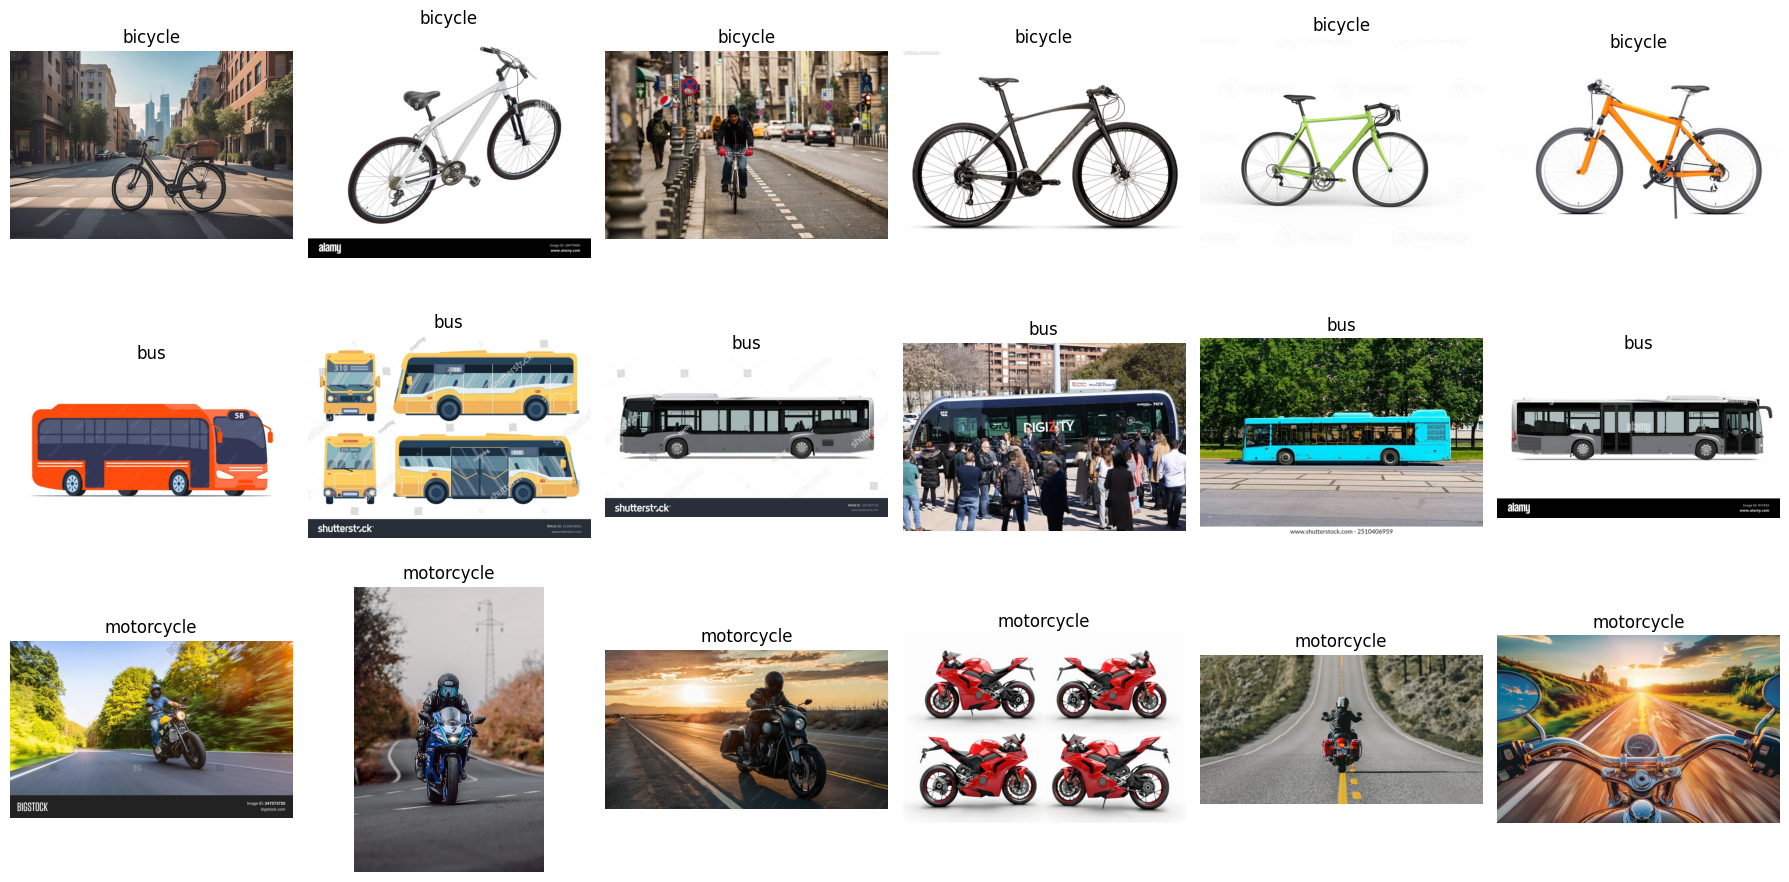

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'bicycle': 71, 'bus': 68, 'motorcycle': 70}
validation {'bicycle': 15, 'bus': 14, 'motorcycle': 15}
test {'bicycle': 16, 'bus': 16, 'motorcycle': 16}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

**Respuesta:**

Porque cada vez que miro el desempeño en `test` y, con base en eso, cambio las épocas, el `learning_rate` o las capas a descongelar, estoy usando `test` para tomar decisiones de entrenamiento. Así la información del test se "filtra" al modelo de manera indirecta: terminaría escogiendo la configuración que funciona mejor justo en esas imágenes, y el accuracy que reporto queda optimista y ya no estima cómo se comportaría con datos realmente nuevos. Para eso existe `validation`: se usa para decidir; `test` se mira una sola vez al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 209 files belonging to 3 classes.
Found 44 files belonging to 3 classes.
Found 48 files belonging to 3 classes.
['bicycle', 'bus', 'motorcycle']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.4115 - loss: 1.1241 - val_accuracy: 0.8864 - val_loss: 0.7171
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.8612 - loss: 0.6289 - val_accuracy: 0.9773 - val_loss: 0.3644
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 47s 4s/step - accuracy: 0.9282 - loss: 0.3933 - val_accuracy: 0.9773 - val_loss: 0.2065
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9474 - loss: 0.2816 - val_accuracy: 0.9773 - val_loss: 0.1330
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9522 - loss: 0.2285 - val_accuracy: 0.9773 - val_loss: 0.0982
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9522 - loss: 0.1940 - val_accuracy: 1.0000 - val_loss: 0.0786
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9665 - loss: 0.1702 - val_accuracy: 0.9773 - val_loss: 0.0678
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9761 - loss: 0.1452 - val_accuracy: 0.9773 - val_loss: 0.0612
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

**Curvas de aprendizaje (primer entrenamiento, cabeza nueva con base congelada):**

- **¿`train_accuracy` subió rápido?** Esperaba que sí, porque EfficientNetB0 ya viene entrenada con ImageNet y conoce formas de vehículos. Y fue así: el accuracy de entrenamiento pasó de 0.41 en la época 1 a 0.86 en la época 2 y llegó a 0.96 en la época 10.
- **Señal de overfitting que busqué:** que `val_loss` empezara a subir mientras `train_loss` bajaba, o que hubiera una brecha grande entre `accuracy` y `val_accuracy`. No apareció ninguna: `val_loss` bajó todo el tiempo (de 0.7171 a 0.0538) y `val_accuracy` quedó por encima del accuracy de entrenamiento. Eso es normal aquí, porque en entrenamiento actúan el `Dropout` y el data augmentation, y el conjunto de validación es muy pequeño (44 imágenes, cada una vale unos 2.3 puntos).
- **Última época (10/10):** accuracy 0.9617, loss 0.1238, val_accuracy 0.9773 y val_loss 0.0538. `EarlyStopping` no se activó, entrenó las 10 épocas.

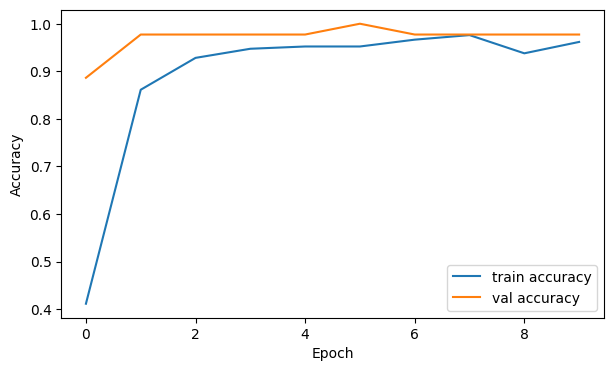

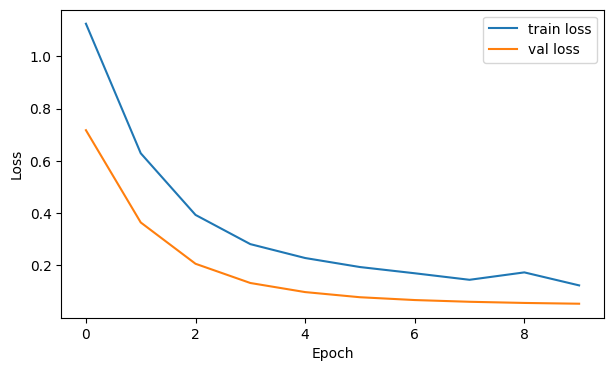

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        16
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



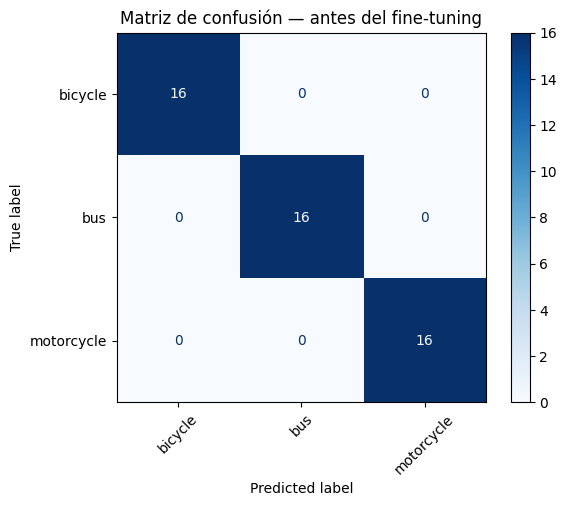

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?
2. ¿Cuál fue la principal confusión?
3. ¿La accuracy global oculta algún problema por clase?
4. ¿Qué cambiarías primero en el **dataset** antes de cambiar el modelo?

**TODO 4 — interpretación de la evaluación:**

1. **Mejor clase:** las tres quedaron empatadas. Bicycle, bus y motorcycle tuvieron precision, recall y F1 de 1.000 (48 de 48 imágenes de test bien clasificadas, `test_acc_before = 1.0000`).
2. **Principal confusión:** ninguna. La matriz de confusión es completamente diagonal (16, 16 y 16) y no hay celdas fuera de la diagonal.
3. **¿La accuracy global oculta algún problema por clase?** No, porque el recall de cada clase también es 1.000. Pero hay que tener cuidado: cada clase tiene solo 16 imágenes en test, así que un 100 % en un conjunto tan pequeño no quiere decir que el modelo sea perfecto; un solo error cambiaría la accuracy en unos 2 puntos.
4. **Qué cambiaría primero en el dataset:** quitaría las imágenes con marcas de agua o banners de texto y las ilustraciones, eliminaría el collage de motos (casi duplicados), y agregaría fotos con fondos más variados (por ejemplo, bicicletas en la calle y motos sobre fondo blanco) para que el modelo no aprenda el fondo. También haría el conjunto de test más grande y más difícil.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

**TODO 5 — justificación de `N_UNFROZEN`:**

Usé `N_UNFROZEN = 20`, el valor de partida que sugiere el taller. Con `BatchNormalization` congelada quedaron 15 de las 238 capas de la base como entrenables. No probé otros valores (10 o 40), así que no puedo decir que 20 sea el mejor, solo que funcionó bien. Con validation: `val_accuracy` se mantuvo en 0.9773 durante las 8 épocas y `val_loss` bajó en todas, de 0.0514 a 0.0398 (venía de 0.0538 al terminar el primer entrenamiento). `EarlyStopping` no se activó. Es decir, adaptar las últimas capas con un `learning_rate` de 1e-5 fue estable y no empeoró nada.

In [18]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stopping_ft],
)

Epoch 1/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9713 - loss: 0.1191 - val_accuracy: 0.9773 - val_loss: 0.0514
Epoch 2/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.9665 - loss: 0.1335 - val_accuracy: 0.9773 - val_loss: 0.0487
Epoch 3/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.9809 - loss: 0.1050 - val_accuracy: 0.9773 - val_loss: 0.0466
Epoch 4/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9713 - loss: 0.1112 - val_accuracy: 0.9773 - val_loss: 0.0440
Epoch 5/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.9713 - loss: 0.1170 - val_accuracy: 0.9773 - val_loss: 0.0423
Epoch 6/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9665 - loss: 0.0999 - val_accuracy: 0.9773 - val_loss: 0.0412
Epoch 7/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.9569 - loss: 0.1185 - val_accuracy: 0.9773 - val_loss: 0.0406
Epoch 8/8
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - accuracy: 0.9761 - loss: 0.0849 - val_accuracy: 0.9773 - val_loss: 0.0398


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


              precision    recall  f1-score   support

     bicycle      1.000     1.000     1.000        16
         bus      1.000     1.000     1.000        16
  motorcycle      1.000     1.000     1.000        16

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48



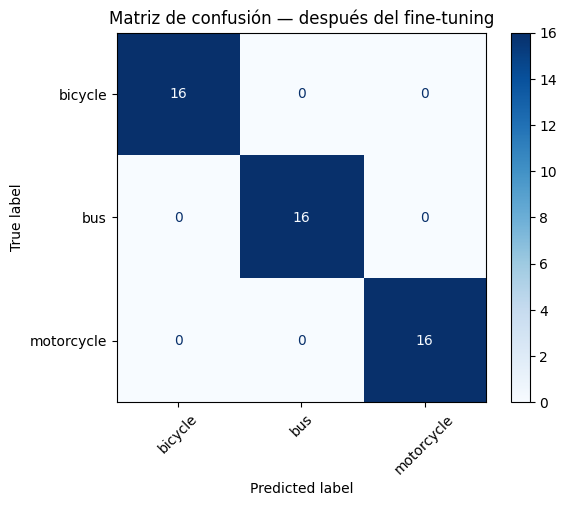

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

No se encontraron errores en este conjunto.


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

**TODO 6 — análisis de errores y conclusiones:**

En el test no hubo errores: `show_mistakes` imprimió "No se encontraron errores en este conjunto." (48 de 48 correctas, antes y después del fine-tuning). Por eso no tengo 5 errores reales del modelo para la tabla. En su lugar, dejo los 5 casos de la inspección del dataset que más podrían causar errores si el test fuera más difícil:

| Caso (de la inspección, no son errores reales) | Clase real | Posible predicción errónea | Causa probable | ¿Cómo lo mejoraría? |
|---|---|---|---|---|
| 1. Bus de caricatura / ilustración vectorial | bus | bicycle o motorcycle | Estilo distinto al de una foto real | Quitar ilustraciones o buscar solo fotos |
| 2. Imágenes con marca de agua o banner de texto (alamy, shutterstock) | cualquiera | cualquiera | El modelo puede usar el texto o el banner como pista | Recortar o eliminar esas imágenes |
| 3. Collage de 4 motos casi idénticas | motorcycle | bicycle | Imagen ambigua con objetos repetidos y pequeños | Eliminarla o separarla en imágenes individuales |
| 4. Bus con una multitud al frente | bus | otra clase | Oclusión: el bus no es lo principal de la imagen | Elegir fotos donde el vehículo sea el protagonista |
| 5. Bicicletas en fondo blanco de catálogo vs. motos en carretera | bicycle / motorcycle | la otra clase | Fondo engañoso: el modelo podría aprender el fondo | Balancear los fondos entre clases |

**Conclusión:**

1. **¿Qué aprendí al construir el dataset?** Que bajar imágenes de un buscador trae datos sucios aunque sean técnicamente válidos (0 inválidas, pero con marcas de agua, ilustraciones y un collage), y que preparar y revisar los datos es una parte tan importante como entrenar el modelo.
2. **Principal problema de calidad:** las marcas de agua y banners con texto, junto con las ilustraciones en la clase bus y el fondo distinto entre clases.
3. **¿Cuánto cambió el desempeño con el fine-tuning?** En test, nada: `test_acc_before = 1.0000` y `test_acc_after = 1.0000` (diferencia de +0.0000). En validation, `val_loss` bajó un poco (de 0.0538 a 0.0398) y `val_accuracy` se quedó en 0.9773.
4. **¿Ayudó el fine-tuning?** En accuracy no, porque ya estaba en 100 % y no había margen para mejorar. La pérdida de validación mejoró levemente, pero con 48 imágenes de test no se puede distinguir una mejora tan pequeña. La tarea es fácil para EfficientNetB0, porque ImageNet ya tiene clases muy cercanas (varios tipos de bus, bicicletas y motos), así que con la cabeza nueva bastaba.
5. **¿Qué mejoraría primero?** Los datos: limpiar marcas de agua, ilustraciones y duplicados, variar los fondos y armar un test más grande y difícil. El modelo ya rinde al máximo en este test, así que ahí está el verdadero cuello de botella.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

### Respuesta (cierre conceptual)

- **Transfer learning con base congelada (feature extraction):** el conocimiento inicial viene de **ImageNet**: EfficientNetB0 ya aprendió, con millones de imágenes, filtros de bordes, texturas y formas. Esos pesos no se tocan. Lo único que se aprende desde cero es la **cabeza nueva** (`Dropout` + `Dense` con softmax), que aprende a combinar esas características para distinguir nuestras tres clases. Se entrenan muy pocos parámetros, así que funciona con pocos datos y es rápido.
- **Fine-tuning:** partimos del mismo conocimiento de ImageNet y de la cabeza ya entrenada, pero ahora además **se actualizan los pesos de las últimas capas** de la base (las más específicas) con un `learning_rate` muy pequeño (1e-5) para adaptarlas a nuestro problema sin destruir lo aprendido. Hay más parámetros aprendiéndose, más riesgo de overfitting en un dataset pequeño y por eso se deja `BatchNormalization` congelada.
- **CNN desde cero:** no hay conocimiento previo; **todos** los pesos (filtros convolucionales y capas finales) parten de valores aleatorios y se aprenden únicamente con nuestro dataset. Necesita muchos más datos y tiempo de entrenamiento para llegar a algo comparable, y con ~300 imágenes casi seguro sobreajusta.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [x] Problema y clases definidos.
- [x] Dataset construido y revisado.
- [x] Train / validation / test creados.
- [x] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [x] Evaluación sobre test.
- [x] Matriz de confusión.
- [x] Precision / recall / F1 interpretados.
- [x] Fine-tuning ejecutado.
- [x] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados (el modelo no cometió errores en test; ver TODO 6).
- [x] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |

---
### Declaración de uso de IA generativa

Herramienta: Claude (Anthropic). Propósito: asistencia en programación (completar los `TODO` de código: entrenamiento de la cabeza, curvas y fine-tuning), propuesta de las clases y términos de búsqueda de ejemplo, y redacción de las respuestas. Las respuestas sobre el dataset, las curvas, la evaluación, el fine-tuning y las conclusiones las redactó Claude a partir de las salidas reales de mi ejecución del notebook en Colab, y yo las revisé.